# Quantum linear systems: gates, normalized output and complete attempts

This original notebook implements HHL on a dyadic commuting matrix and a spectrum-matched QSVT inverse. Both prepare a normalized solution state and estimate $Z(q_0)$; neither returns every entry of the classical vector. Dense solves below are independent bounded references, never quantum gates. Qiskit2.6.2 is Apache2.0; NumPy2.5.4/SciPy1.18.1 are BSD3Clause; our source is MIT. The chapter cites HHL and QSVT primary papers.

In [1]:
from pathlib import Path
import sys, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import Statevector
root=Path.cwd()
if not (root/'src/openquantum/linear_systems.py').exists() and (root.parent/'src/openquantum/linear_systems.py').exists():
    root=root.parent
if (root/'src/openquantum/linear_systems.py').exists():
    sys.path.insert(0,str(root/'src'))
elif (root/'code/src/openquantum/linear_systems.py').exists():
    sys.path.insert(0,str(root/'code/src'))
from openquantum import linear_systems as hhl
from openquantum import linear_systems_qsvt as qsvt
system=hhl.GridXSystem()
A=hhl.dense_matrix(system)
b=np.array([1.,0.])
x=np.linalg.solve(A,b)
print('A =',A,'classical x =',x,'normalized =',x/np.linalg.norm(x))

A = [[ 0.375 -0.125]
 [-0.125  0.375]] classical x = [3. 1.] normalized = [0.9486833  0.31622777]


## Actual HHL access, phase register and reciprocal rotation

$A=\tfrac14 I+\tfrac14(I-X)/2$, eigenvalues1/4,1/2. Controlled evolution contains the identity-component control phase and controlled RX gates. The two clock bits represent the eigenvalues exactly; the success flag rotation multiplies amplitudes by $(1/4)/\lambda$. The inverse QPE erases the clock. Every attempt measures all wires at the end.

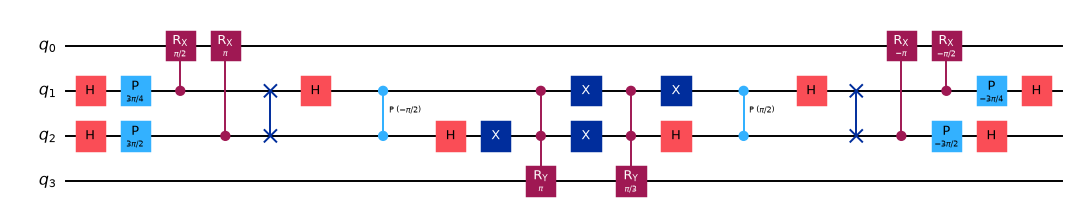

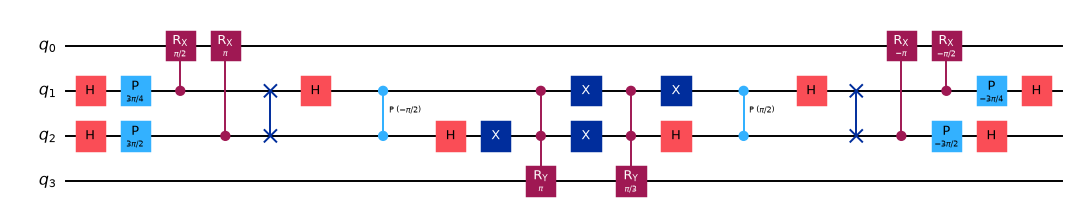

In [2]:
circuit=hhl.build_hhl(system)
display(circuit.draw(output='mpl',fold=22,scale=.7))

In [3]:
result=hhl.compare_hhl(system)
assert result['trace_distance_to_normalized_classical_solution']<1e-12
assert abs(result['success_probability']-.625)<1e-12
assert abs(result['quantum_observable']-.8)<1e-12
display(pd.DataFrame([{'success':result['success_probability'],'solution trace distance':result['trace_distance_to_normalized_classical_solution'],'Z quantum':result['quantum_observable'],'Z classical':result['classical_observable']}]))

,success,solution trace distance,Z quantum,Z classical
0,0.625,3.687126e-18,0.8,0.8


## Modern QSVT: an implemented spectrum-matched variant

The normalized matrix is $B=A/(1/2)=.75I-.25X$. Three explicit Pauli block encodings and four projector phases implement $p(B)$ with $p(x)=(5x-4x^3)/4$. At the specified eigenvalues1/2,1, $p(x)=1/(4x)$, so the accepted state is the same solution. Away from these eigenvalues this cubic is **not** a general high-accuracy inverse.

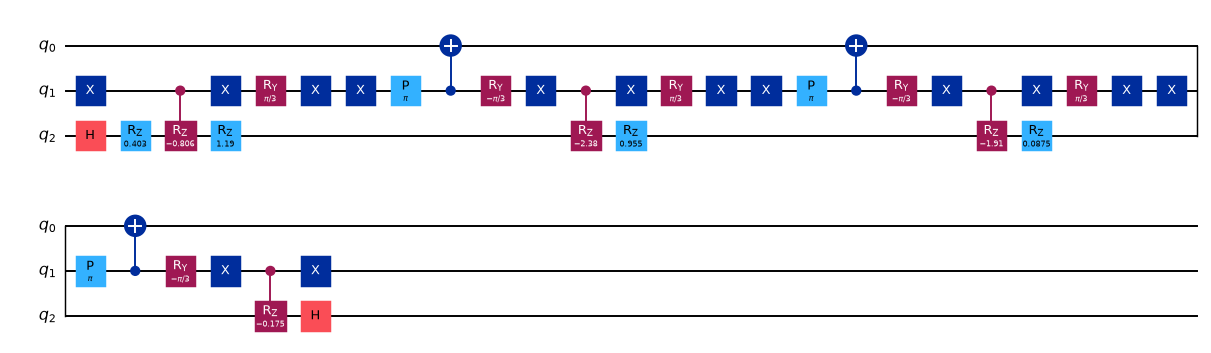

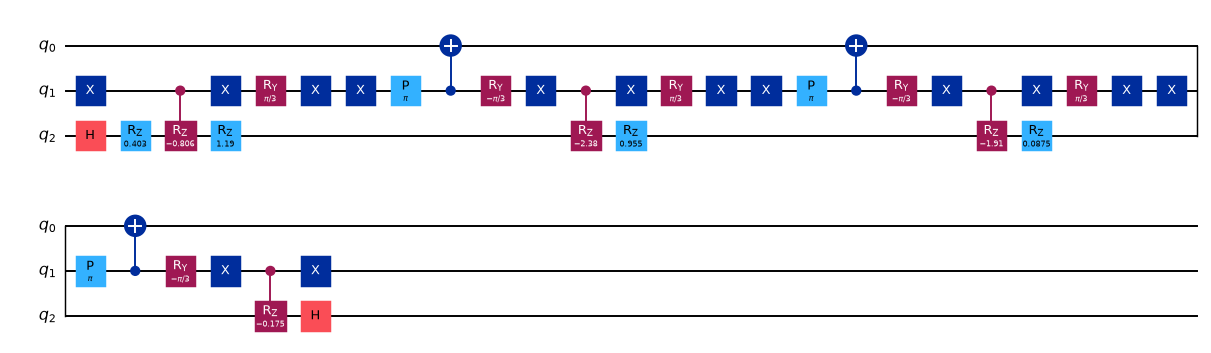

In [4]:
terms=qsvt.DEFAULT_TERMS
filter_circuit=qsvt.build_inverse_qsvt(terms)
display(filter_circuit.draw(output='mpl',fold=25,scale=.7))

In [5]:
qresult=qsvt.compare_inverse_qsvt(terms)
phase=qsvt.verify_inverse_phases()
assert qresult['solution_state_trace_distance']<1e-12
assert abs(qresult['acceptance_probability']-5/32)<1e-12
assert phase['dense_grid_max_phase_error']<1e-12
display(pd.DataFrame([{'method':'HHL','logical qubits':4,'acceptance':result['success_probability'],'Z':result['quantum_observable']},{'method':'cubic QSVT','logical qubits':3,'acceptance':qresult['acceptance_probability'],'Z':qresult['z_actual']}]))

,method,logical qubits,acceptance,Z
0,HHL,4,0.62500,0.8
1,cubic QSVT,3,0.15625,0.8


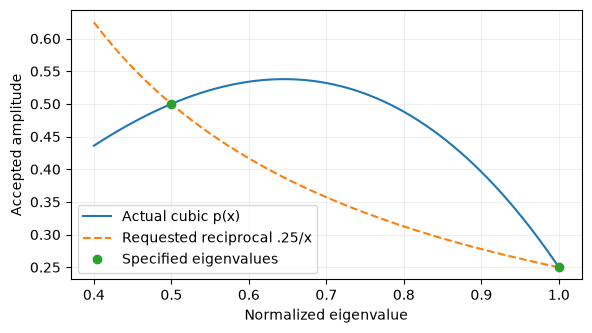

Max reciprocal error on [.5,1]: 0.1822959075956836


In [6]:
grid=np.linspace(.4,1,401)
fig,ax=plt.subplots(figsize=(6.6,3.5))
ax.plot(grid,qsvt.inverse_polynomial(grid),label='Actual cubic p(x)')
ax.plot(grid,.25/grid,'--',label='Requested reciprocal .25/x')
ax.plot([.5,1],[.5,.25],'o',label='Specified eigenvalues')
ax.set(xlabel='Normalized eigenvalue',ylabel='Accepted amplitude')
ax.grid(alpha=.2);ax.legend();plt.show()
print('Max reciprocal error on [.5,1]:',phase['reciprocal_max_error_interval_0_5_to_1'])

## Complete measured attempts and fresh-trial repetitions

We include the input gates, every access and uncomputation, actual output basis changes, and final data/ancilla measurements. Rejecting an ancilla result does not remove its cost. The following counts precede Clifford+T synthesis. The capped workload is an **unexecuted ideal proposal**, with independent .005 statistical and .005 no-acceptance allowances. It is not a hardware confidence certificate.

In [7]:
rows=[]
for name,c,p in [('HHL',hhl.measured_hhl_trial(system),result['success_probability']),('QSVT',qsvt.qsvt_measured_trial(),qresult['acceptance_probability'])]:
    compiled=hhl.decompose(c)
    workload=hhl.accepted_observable_workload(p)
    rows.append({'method':name,'logical qubits':compiled.num_qubits,'CX':compiled.count_ops().get('cx',0),'rotations':sum(compiled.count_ops().get(g,0) for g in ('rx','ry','rz')),'measurements':compiled.count_ops()['measure'],'accepted samples':workload['accepted_samples'],'attempts per slot':workload['attempt_cap_per_accepted_slot'],'capped attempts':workload['total_capped_attempts']})
display(pd.DataFrame(rows))

,method,logical qubits,CX,rotations,measurements,accepted samples,attempts per slot,capped attempts
0,HHL,4,34,32,4,13315,16,213040
1,QSVT,3,11,12,3,13315,88,1171720


## Reproducible variation

A slider regenerates and checks a product input on the same matrix. Live controls need a Python kernel; static publication retains the checked outputs above. Generation of larger structured circuits is separate from the bounded simulator.

In [8]:
if not os.environ.get('OPENQUANTUM_STATIC_BUILD'):
    import ipywidgets as widgets
    def check_input(angle=0.):
        r=hhl.compare_hhl(system,angles=(angle,))
        assert r['trace_distance_to_normalized_classical_solution']<1e-12
        display(pd.DataFrame([{'input RY':angle,'success':r['success_probability'],'Z':r['quantum_observable']}]))
    display(widgets.interactive(check_input,angle=widgets.FloatSlider(min=-1.5,max=1.5,step=.1,value=0.)))